In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
os.makedirs('charts', exist_ok=True)

In [2]:
df = pd.read_csv("raw_retail_sales_data (1).csv")

In [7]:
df

,Order_ID,Order_Date,Customer_ID,Region,City,Category,Product,Quantity,Unit_Price,Unit_Cost,Discount_Pct,Payment_Mode,Sales_Channel
0,ORD1160,28-08-2025,CUST052,East,Bhubaneswar,HOME & KITCHEN,Water Bottle,3,449,240,15.0,UPI,Online
1,ORD1299,31-12-2025,CUST099,North,Agra,Office Supplies,Desk Organizer,2,599,350,5.0,NaN,Online
2,ORD1266,02-12-2025,CUST109,north,Delhi,Clothing,Winter Jacket,2,2999,1900,10.0,UPI,Online
3,ORD1244,19-11-2025,CUST014,North,Lucknow,Furniture,Study Table,1,4999,3400,0.0,UPI,Offline
4,ORD1195,02-10-2025,CUST066,East,Kolkata,Home & Kitchen,Electric Kettle,3,999,620,5.0,Credit Card,Online
...,...,...,...,...,...,...,...,...,...,...,...,...,...
305,ORD1278,14-12-2025,CUST031,north,Jaipur,Furniture,Office Chair,2,6499,4300,10.0,Credit Card,Online
306,ORD1257,27-11-2025,CUST071,South,Chennai,clothing,Sports Shoes,3,2499,1500,10.0,Credit Card,Online
307,ORD1132,13-07-2025,CUST037,North,Agra,Office Supplies,Stapler Set,2,299,170,0.0,UPI,Online
308,ORD1250,23-11-2025,CUST111,West,Pune,Furniture,Study Table,2,4999,3400,0.0,Credit Card,Offline


In [9]:
df.shape

(310, 13)

In [10]:
df.isnull().sum()

Order_ID         0
Order_Date       0
Customer_ID      0
Region           9
City             0
Category         0
Product          0
Quantity         0
Unit_Price       0
Unit_Cost        0
Discount_Pct     8
Payment_Mode     7
Sales_Channel    0
dtype: int64

In [11]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       310 non-null    object 
 1   Order_Date     310 non-null    object 
 2   Customer_ID    310 non-null    object 
 3   Region         301 non-null    object 
 4   City           310 non-null    object 
 5   Category       310 non-null    object 
 6   Product        310 non-null    object 
 7   Quantity       310 non-null    int64  
 8   Unit_Price     310 non-null    int64  
 9   Unit_Cost      310 non-null    int64  
 10  Discount_Pct   302 non-null    float64
 11  Payment_Mode   303 non-null    object 
 12  Sales_Channel  310 non-null    object 
dtypes: float64(1), int64(3), object(9)
memory usage: 31.6+ KB


In [13]:
print(df.isnull().sum()[df.isnull().sum() > 0])

Region          9
Discount_Pct    8
Payment_Mode    7
dtype: int64


In [12]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 10


In [15]:
print('\nCategory values:', df['Category'].unique())



Category values: ['HOME & KITCHEN' 'Office Supplies' 'Clothing' 'Furniture'
 'Home & Kitchen' 'Electronics' ' furniture ' ' office supplies '
 ' home & kitchen ' 'ELECTRONICS' ' clothing ' ' electronics ' 'FURNITURE'
 'OFFICE SUPPLIES' 'CLOTHING']


In [16]:
print('\nRegion values:', df['Region'].unique())


Region values: ['East' 'North' 'north' 'South' 'West' 'west' 'North ' 'East ' nan
 'South ' 'south' 'West ']


In [17]:
print('\nInvalid quantity (<= 0):', (df['Quantity'] <= 0).sum())


Invalid quantity (<= 0): 3


In [18]:
print('\nDate samples (mixed formats):', df['Order_Date'].sample(6, random_state=1).tolist())


Date samples (mixed formats): ['21-11-2025', '04-02-2025', '13-07-2025', '14-Apr-25', '24-Dec-25', '11-10-2025']


In [19]:
%%html
<h3> Data Cleaning </h3>

In [20]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplicates removed: {before - len(df)}')

Duplicates removed: 10


In [21]:
for col in ['Region', 'City', 'Category', 'Product', 'Payment_Mode', 'Sales_Channel']:
    df[col] = df[col].str.strip().str.title()

print(df['Category'].unique())
print(df['Region'].unique())

['Home & Kitchen' 'Office Supplies' 'Clothing' 'Furniture' 'Electronics']
['East' 'North' 'South' 'West' nan]


In [22]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'], format='mixed', dayfirst=True)
print('Date range:', df['Order_Date'].min().date(), 'to', df['Order_Date'].max().date())

Date range: 2025-01-01 to 2025-12-31


In [23]:
city_to_region = df.dropna(subset=['Region']).groupby('City')['Region'].first()
df['Region'] = df['Region'].fillna(df['City'].map(city_to_region))

# Payment_Mode -> 'Unknown'
df['Payment_Mode'] = df['Payment_Mode'].fillna('Unknown')

# Discount_Pct -> 0 (assumption: discount record nahi hua = no discount)
df['Discount_Pct'] = df['Discount_Pct'].fillna(0)

print('Missing values left:', df.isnull().sum().sum())

Missing values left: 0


In [24]:
bad = df['Quantity'] <= 0
print(f'Invalid quantity rows removed: {bad.sum()}')
df = df[~bad]

Invalid quantity rows removed: 3


In [25]:
df['Total_Sales'] = (df['Quantity'] * df['Unit_Price'] * (1 - df['Discount_Pct'] / 100)).round(2)
df['Profit'] = (df['Total_Sales'] - df['Quantity'] * df['Unit_Cost']).round(2)
df['Month_Num'] = df['Order_Date'].dt.month
df['Month'] = df['Order_Date'].dt.strftime('%b')
df['Quarter'] = 'Q' + df['Order_Date'].dt.quarter.astype(str)
df['Profit_Margin_Pct'] = (df['Profit'] / df['Total_Sales'] * 100).round(2)

df = df.sort_values('Order_Date').reset_index(drop=True)

In [27]:
df.head()

,Order_ID,Order_Date,Customer_ID,Region,City,Category,Product,Quantity,Unit_Price,Unit_Cost,Discount_Pct,Payment_Mode,Sales_Channel,Total_Sales,Profit,Month_Num,Month,Quarter,Profit_Margin_Pct
0,ORD1001,2025-01-01,CUST006,West,Mumbai,Clothing,Sports Shoes,2,2499,1500,5.0,Upi,Offline,4748.10,1748.10,1,Jan,Q1,36.82
1,ORD1002,2025-01-02,CUST046,West,Mumbai,Home & Kitchen,Cookware Set,3,2799,1800,10.0,Cash On Delivery,Offline,7557.30,2157.30,1,Jan,Q1,28.55
2,ORD1003,2025-01-04,CUST104,South,Chennai,Home & Kitchen,Cookware Set,4,2799,1800,20.0,Upi,Online,8956.80,1756.80,1,Jan,Q1,19.61
3,ORD1004,2025-01-04,CUST104,North,Lucknow,Clothing,Winter Jacket,3,2999,1900,15.0,Upi,Online,7647.45,1947.45,1,Jan,Q1,25.47
4,ORD1005,2025-01-05,CUST059,East,Guwahati,Home & Kitchen,Electric Kettle,1,999,620,15.0,Upi,Offline,849.15,229.15,1,Jan,Q1,26.99


In [30]:

print('Missing values:', df.isnull().sum().sum())
print('Duplicates:', df.duplicated().sum())
df.head()

Missing values: 0
Duplicates: 0


,Order_ID,Order_Date,Customer_ID,Region,City,Category,Product,Quantity,Unit_Price,Unit_Cost,Discount_Pct,Payment_Mode,Sales_Channel,Total_Sales,Profit,Month_Num,Month,Quarter,Profit_Margin_Pct
0,ORD1001,2025-01-01,CUST006,West,Mumbai,Clothing,Sports Shoes,2,2499,1500,5.0,Upi,Offline,4748.10,1748.10,1,Jan,Q1,36.82
1,ORD1002,2025-01-02,CUST046,West,Mumbai,Home & Kitchen,Cookware Set,3,2799,1800,10.0,Cash On Delivery,Offline,7557.30,2157.30,1,Jan,Q1,28.55
2,ORD1003,2025-01-04,CUST104,South,Chennai,Home & Kitchen,Cookware Set,4,2799,1800,20.0,Upi,Online,8956.80,1756.80,1,Jan,Q1,19.61
3,ORD1004,2025-01-04,CUST104,North,Lucknow,Clothing,Winter Jacket,3,2999,1900,15.0,Upi,Online,7647.45,1947.45,1,Jan,Q1,25.47
4,ORD1005,2025-01-05,CUST059,East,Guwahati,Home & Kitchen,Electric Kettle,1,999,620,15.0,Upi,Offline,849.15,229.15,1,Jan,Q1,26.99


In [31]:
%%html
<h3> KPI </h3>

In [32]:
total_sales   = df['Total_Sales'].sum()
total_profit  = df['Profit'].sum()
total_orders  = df['Order_ID'].nunique()
total_units   = df['Quantity'].sum()
aov           = total_sales / total_orders
margin        = total_profit / total_sales * 100
customers     = df['Customer_ID'].nunique()

kpi = pd.DataFrame({
    'KPI': ['Total Sales (INR)', 'Total Profit (INR)', 'Profit Margin (%)',
            'Total Orders', 'Units Sold', 'Avg Order Value (INR)', 'Unique Customers'],
    'Value': [round(total_sales), round(total_profit), round(margin, 2),
              total_orders, total_units, round(aov), customers]
})
kpi

,KPI,Value
0,Total Sales (INR),1045226.00
1,Total Profit (INR),321696.00
2,Profit Margin (%),30.78
3,Total Orders,297.00
4,Units Sold,605.00
5,Avg Order Value (INR),3519.00
6,Unique Customers,108.00


In [33]:
%%html
<h3> Monthly Trend</h3>

In [34]:
monthly = (df.groupby(['Month_Num', 'Month'])
             .agg(Sales=('Total_Sales', 'sum'), Profit=('Profit', 'sum'), Orders=('Order_ID', 'count'))
             .reset_index()
             .sort_values('Month_Num'))
monthly

,Month_Num,Month,Sales,Profit,Orders
0,1,Jan,63310.40,18320.40,18
1,2,Feb,69855.95,21695.95,21
2,3,Mar,55878.20,16768.20,17
3,4,Apr,124352.75,39302.75,28
4,5,May,98544.65,29544.65,27
5,6,Jun,28413.65,9133.65,11
6,7,Jul,87698.95,27108.95,23
7,8,Aug,49761.85,15091.85,20
8,9,Sep,101628.30,32598.30,27
9,10,Oct,121314.75,38504.75,34


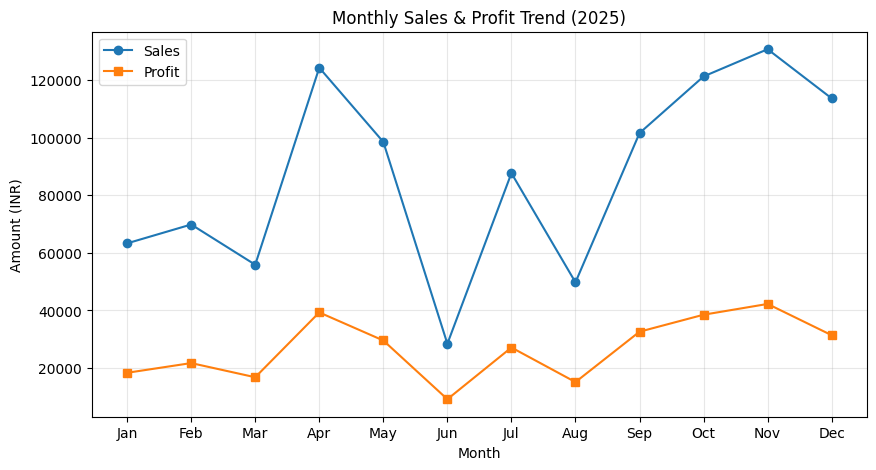

Best month: Nov (INR 130,777)
Weakest month: Jun (INR 28,414)


In [35]:
plt.plot(monthly['Month'], monthly['Sales'], marker='o', label='Sales')
plt.plot(monthly['Month'], monthly['Profit'], marker='s', label='Profit')
plt.title('Monthly Sales & Profit Trend (2025)')
plt.xlabel('Month'); plt.ylabel('Amount (INR)')
plt.legend()
plt.savefig('charts/monthly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

best = monthly.loc[monthly['Sales'].idxmax()]
worst = monthly.loc[monthly['Sales'].idxmin()]
print(f"Best month: {best['Month']} (INR {best['Sales']:,.0f})")
print(f"Weakest month: {worst['Month']} (INR {worst['Sales']:,.0f})")

In [36]:
%%html
<h3>Category Analysis</h3>

In [37]:
cat = (df.groupby('Category')
         .agg(Sales=('Total_Sales', 'sum'), Profit=('Profit', 'sum'), Units=('Quantity', 'sum'))
         .sort_values('Sales', ascending=False))
cat['Margin_%'] = (cat['Profit'] / cat['Sales'] * 100).round(1)
cat['Sales_Share_%'] = (cat['Sales'] / cat['Sales'].sum() * 100).round(1)
cat

,Sales,Profit,Units,Margin_%,Sales_Share_%
Category,,,,,
Furniture,349171.95,99971.95,84,28.6,33.4
Home & Kitchen,235489.55,71469.55,116,30.3,22.5
Electronics,205067.25,61017.25,132,29.8,19.6
Clothing,200523.50,69533.50,110,34.7,19.2
Office Supplies,54973.70,19703.70,163,35.8,5.3


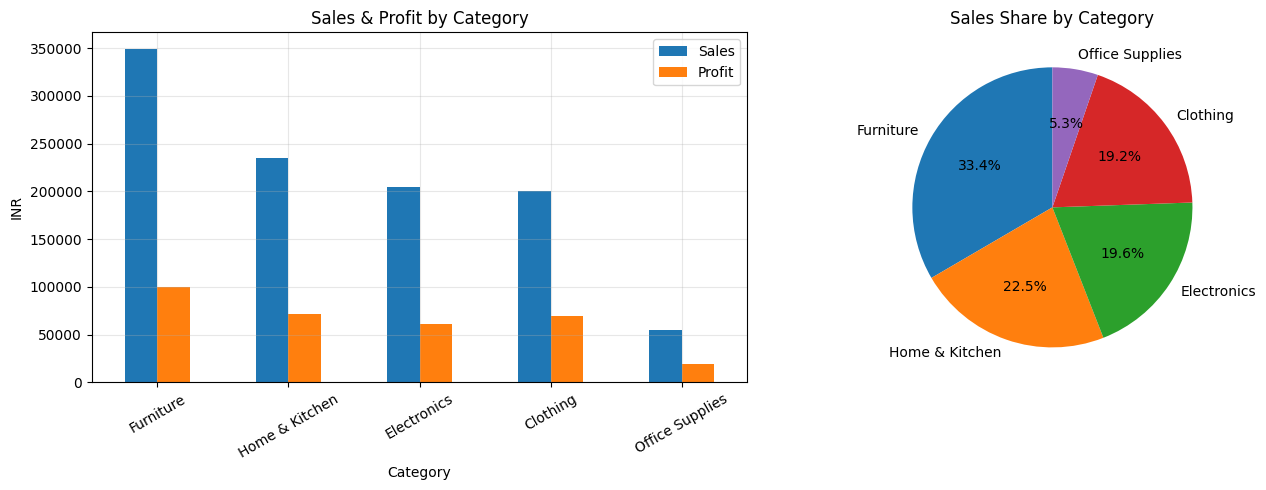

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cat[['Sales', 'Profit']].plot(kind='bar', ax=ax[0])
ax[0].set_title('Sales & Profit by Category'); ax[0].set_ylabel('INR'); ax[0].tick_params(axis='x', rotation=30)
ax[1].pie(cat['Sales'], labels=cat.index, autopct='%1.1f%%', startangle=90)
ax[1].set_title('Sales Share by Category')
plt.tight_layout()
plt.savefig('charts/category.png', dpi=150, bbox_inches='tight')
plt.show()

In [39]:
%%html
<h3> Product Analysis</h3>

In [40]:
prod = (df.groupby(['Product', 'Category'])
          .agg(Sales=('Total_Sales', 'sum'), Profit=('Profit', 'sum'), Units=('Quantity', 'sum'))
          .reset_index()
          .sort_values('Sales', ascending=False))
print('TOP 5 PRODUCTS')
display(prod.head(5))
print('BOTTOM 5 PRODUCTS')
display(prod.tail(5))

TOP 5 PRODUCTS


,Product,Category,Sales,Profit,Units
20,Study Table,Furniture,127974.40,36174.40,27
12,Mixer Grinder,Home & Kitchen,112660.85,31260.85,37
14,Office Chair,Furniture,111457.85,34057.85,18
22,Winter Jacket,Clothing,109613.45,35513.45,39
3,Cookware Set,Home & Kitchen,73753.65,23353.65,28


BOTTOM 5 PRODUCTS


,Product,Category,Sales,Profit,Units
19,Stapler Set,Office Supplies,9388.60,3608.60,34
16,Printer Paper Ream,Office Supplies,8418.90,1748.90,23
13,Notebook Pack,Office Supplies,8391.30,3351.30,36
21,Water Bottle,Home & Kitchen,6308.45,2708.45,15
10,Gel Pen Box,Office Supplies,5084.45,2004.45,28


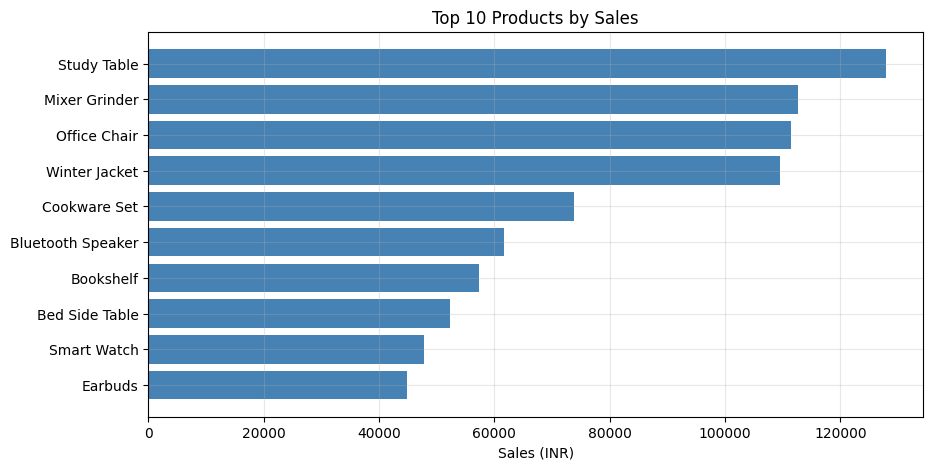

In [41]:
top10 = prod.head(10).sort_values('Sales')
plt.barh(top10['Product'], top10['Sales'], color='steelblue')
plt.title('Top 10 Products by Sales'); plt.xlabel('Sales (INR)')
plt.savefig('charts/top_products.png', dpi=150, bbox_inches='tight')
plt.show()

In [42]:
%%html
<h3> Regional performance </h3>

In [44]:
reg = (df.groupby('Region')
         .agg(Sales=('Total_Sales', 'sum'), Profit=('Profit', 'sum'), Orders=('Order_ID', 'count'))
         .sort_values('Sales', ascending=False))
reg['Avg_Order_Value'] = (reg['Sales'] / reg['Orders']).round(0)
reg

,Sales,Profit,Orders,Avg_Order_Value
Region,,,,
West,336817.50,104057.50,91,3701.0
North,320232.75,99252.75,89,3598.0
South,299706.85,89426.85,80,3746.0
East,88468.85,28958.85,37,2391.0


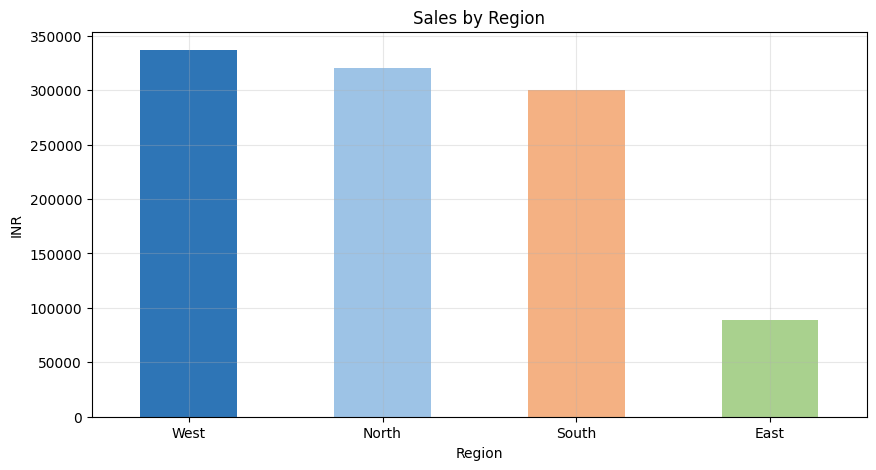

Top 5 cities:
City
Jaipur       117320.0
Chennai      111406.0
Ahmedabad    102072.0
Pune          95066.0
Mumbai        81723.0
Name: Total_Sales, dtype: float64


In [45]:
reg['Sales'].plot(kind='bar', color=['#2E75B6', '#9DC3E6', '#F4B183', '#A9D18E'])
plt.title('Sales by Region'); plt.ylabel('INR'); plt.xticks(rotation=0)
plt.savefig('charts/region.png', dpi=150, bbox_inches='tight')
plt.show()

city = df.groupby('City')['Total_Sales'].sum().sort_values(ascending=False).head(5)
print('Top 5 cities:'); print(city.round(0))

In [47]:
%%html
<h3>Online Vs Offline</h3>

,Sales,Orders,Share_%
Sales_Channel,,,
Offline,460854.80,126,44.1
Online,584371.15,171,55.9


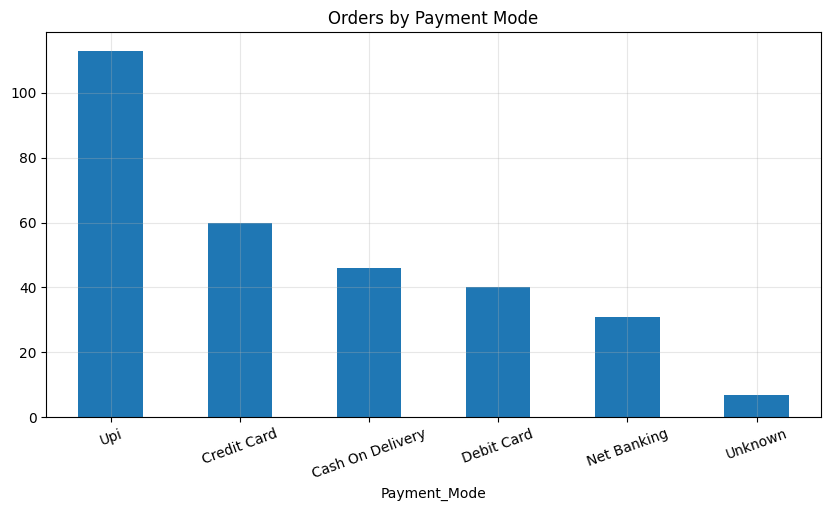

In [46]:
chan = df.groupby('Sales_Channel').agg(Sales=('Total_Sales', 'sum'), Orders=('Order_ID', 'count'))
chan['Share_%'] = (chan['Sales'] / chan['Sales'].sum() * 100).round(1)
display(chan)

pay = df.groupby('Payment_Mode')['Order_ID'].count().sort_values(ascending=False)
pay.plot(kind='bar'); plt.title('Orders by Payment Mode'); plt.xticks(rotation=20)
plt.savefig('charts/payment.png', dpi=150, bbox_inches='tight')
plt.show()

In [49]:
%%html
<h3> Discount Impact</h3>

In [48]:
disc = (df.groupby('Discount_Pct')
          .agg(Orders=('Order_ID', 'count'), Sales=('Total_Sales', 'sum'), Profit=('Profit', 'sum')))
disc['Margin_%'] = (disc['Profit'] / disc['Sales'] * 100).round(1)
disc

,Orders,Sales,Profit,Margin_%
Discount_Pct,,,,
0.0,98,368406.00,130636.00,35.5
5.0,66,229302.45,74592.45,32.5
10.0,71,267923.70,75623.70,28.2
15.0,34,113114.60,27734.60,24.5
20.0,28,66479.20,13109.20,19.7


In [51]:
%%html
<h3> Reapeat Customers Analysis </h3>

In [50]:
cust = df.groupby('Customer_ID').agg(Orders=('Order_ID', 'count'), Spend=('Total_Sales', 'sum'))
repeat = (cust['Orders'] > 1).sum()
print(f"Repeat customers: {repeat} out of {len(cust)} ({repeat/len(cust)*100:.1f}%)")
print('\nTop 5 customers by spend:')
cust.sort_values('Spend', ascending=False).head(5).round(0)

Repeat customers: 84 out of 108 (77.8%)

Top 5 customers by spend:


,Orders,Spend
Customer_ID,,
CUST108,5,31166.0
CUST014,6,30646.0
CUST046,3,26399.0
CUST102,6,25442.0
CUST116,3,24932.0


In [53]:
%%html
<h3> Key Insights </h3>

In [52]:
top_cat = cat.index[0]
low_cat = cat.index[-1]
top_prod = prod.iloc[0]['Product']
top_reg = reg.index[0]
low_reg = reg.index[-1]
best_margin_cat = cat['Margin_%'].idxmax()

print("KEY INSIGHTS")
print("-" * 60)
print(f"1. Total sales INR {total_sales:,.0f} with profit INR {total_profit:,.0f} (margin {margin:.1f}%).")
print(f"2. {best['Month']} was the best month; {worst['Month']} was the weakest.")
print(f"3. '{top_cat}' is the top category ({cat.loc[top_cat, 'Sales_Share_%']}% of sales); '{low_cat}' is the lowest.")
print(f"4. '{best_margin_cat}' has the highest profit margin ({cat.loc[best_margin_cat, 'Margin_%']}%).")
print(f"5. Top product by sales: {top_prod}.")
print(f"6. {top_reg} region leads; {low_reg} region has the lowest sales.")
print(f"7. Online contributes {chan.loc['Online', 'Share_%']}% of sales.")

KEY INSIGHTS
------------------------------------------------------------
1. Total sales INR 1,045,226 with profit INR 321,696 (margin 30.8%).
2. Nov was the best month; Jun was the weakest.
3. 'Furniture' is the top category (33.4% of sales); 'Office Supplies' is the lowest.
4. 'Office Supplies' has the highest profit margin (35.8%).
5. Top product by sales: Study Table.
6. West region leads; East region has the lowest sales.
7. Online contributes 55.9% of sales.


In [54]:
df.to_csv('cleaned_retail_sales.csv', index=False)

with pd.ExcelWriter('analysis_summary.xlsx') as writer:
    kpi.to_excel(writer, sheet_name='KPIs', index=False)
    monthly.to_excel(writer, sheet_name='Monthly', index=False)
    cat.to_excel(writer, sheet_name='Category')
    prod.to_excel(writer, sheet_name='Products', index=False)
    reg.to_excel(writer, sheet_name='Region')
print('Saved: cleaned_retail_sales.csv, analysis_summary.xlsx, charts/*.png')

Saved: cleaned_retail_sales.csv, analysis_summary.xlsx, charts/*.png
